# Task 3 · Midterm Project: Bank Marketing, term deposit
**Author:** Baizhan  **SEED:** 3101

The notebook runs top to bottom with Restart & Run All.

## Stage 1 · Framing

**Business question.** The bank phones clients to sell a term deposit. In one wave the call centre can phone only 10% of the list. The model must rank clients by the probability of "yes" so that the called 10% contains as many buyers as possible. Scoring happens before any call.

**Metric.** Only the ranking matters because exactly the top 10% are called. Main metrics: ROC-AUC and average precision; for the decision: precision@10%, recall@10% and lift over random calling. Accuracy is not used because a model that always says "no" already gets 88.7%.

**Train vs test columns.** `y` and `duration` exist only in train. `y` is the answer we predict. `duration` is the length of the call, which is known only after the call is made, but scoring is done before any call. Consequence: `duration` must not be a feature (it would inflate the scores and could not be computed in real use). `id` is in both files but is only an identifier, so it is dropped as well.

In [18]:
import sys, os, sklearn, numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

SEED = 3101
print(sys.version)
print("sklearn", sklearn.__version__, "numpy", np.__version__, "pandas", pd.__version__, "SEED", SEED)

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print(train.shape, test.shape)
print("only in train:", set(train.columns) - set(test.columns))
print("only in test:", set(test.columns) - set(train.columns))

3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]
sklearn 1.7.2 numpy 2.3.4 pandas 2.3.3 SEED 3101
(32940, 22) (8236, 20)
only in train: {'y', 'duration'}
only in test: set()


## Stage 2 · EDA

**Class balance.** "yes" = 11.27% (3 711 of 32 940 rows), "no" = 88.73%. A classifier that always answers "no" gets accuracy 0.887, so accuracy is misleading here: it looks high while the model finds no buyers at all (Stage 5 confirms this: ROC-AUC 0.5).

**"Missing" values and the sentinel (counts).**

| Column | Value | Rows | Share |
|---|---|---|---|
| default | "unknown" | 6 871 | 20.9% |
| education | "unknown" | 1 401 | 4.3% |
| housing | "unknown" | 794 | 2.4% |
| loan | "unknown" | 794 | 2.4% |
| job | "unknown" | 275 | 0.8% |
| marital | "unknown" | 64 | 0.2% |
| pdays | 999 | 31 694 | 96.2% |

"unknown" means the client's answer is not recorded. `pdays == 999` is a code for "not contacted in a previous campaign", not a real number of days.

**Row order.** The month changes between neighbouring rows 26 442 times out of 32 939 transitions (80%), so the rows are shuffled and do not follow time. This means shuffled cross-validation is fine, but it also means the data cannot be split "past vs future", so my validation cannot test time drift (discussed in Stage 7).

**Plots and numeric observations.**
1. *"yes" rate by `poutcome`:* clients whose previous campaign was a success say "yes" in 64.8% of cases, after a failure 14.0%, and with no previous campaign ("nonexistent") only 8.8%. The base rate is 11.3%, so a previous success makes a "yes" about 5.7 times more likely than average.
2. *`euribor3m` by y:* the median interest rate is 1.266 for "yes" clients and 4.857 for "no" clients. Buyers are concentrated in periods with low rates (the "yes" box reaches down to about 0.8, the "no" box starts at about 1.4).

**Summary.** The strongest signals are `poutcome` and `euribor3m`. Two cautions: (1) `euribor3m` (and similar economic columns such as `nr.employed`) mostly tells *when* the call happened, so it acts as a time proxy; with a random split this helps the model more than it would in the future. (2) `duration` is excluded because it is known only after the call (Stage 1).

yes share: 0.11265938069216758 | yes rows: 3711 | majority accuracy: 0.8873406193078324
           count     share
job          275  0.008349
marital       64  0.001943
education   1401  0.042532
default     6871  0.208591
housing      794  0.024104
loan         794  0.024104
pdays==999: 31694 0.9621736490588949
month changes: 26442 of 32939
poutcome
failure        0.140309
nonexistent    0.088132
success        0.647788
Name: y, dtype: float64


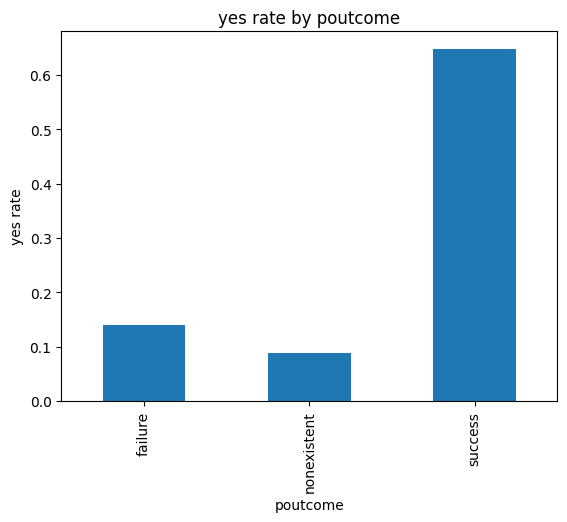

y
no     4.857
yes    1.266
Name: euribor3m, dtype: float64


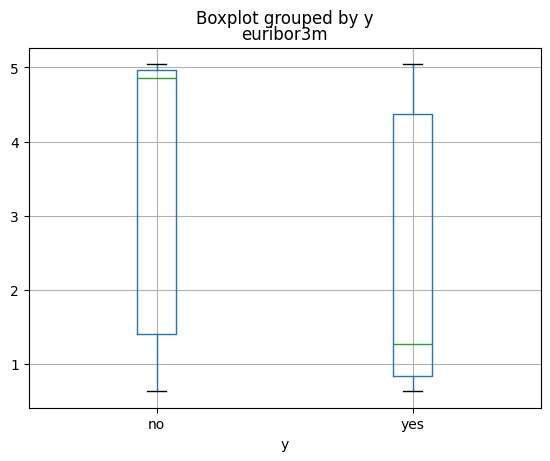

In [19]:
y = (train["y"] == "yes").astype(int)
print("yes share:", y.mean(), "| yes rows:", y.sum(), "| majority accuracy:", 1 - y.mean())

obj = train.select_dtypes(exclude="number").columns.drop("y")
u = (train[obj] == "unknown").sum().loc[lambda s: s > 0]
print(pd.DataFrame({"count": u, "share": u / len(train)}))
print("pdays==999:", (train["pdays"] == 999).sum(), (train["pdays"] == 999).mean())
print("month changes:", (train["month"] != train["month"].shift()).sum(), "of", len(train) - 1)

rate = train.groupby("poutcome")["y"].apply(lambda s: (s == "yes").mean())
print(rate)
rate.plot.bar(); plt.ylabel("yes rate"); plt.title("yes rate by poutcome"); plt.show()
print(train.groupby("y")["euribor3m"].median())
train.boxplot(column="euribor3m", by="y"); plt.show()

## Stage 3 · Validation design

`train.csv` (32 940 rows) is split into **dev** (26 352 rows, 80%) and **hold-out** (6 588 rows, 20%) with `train_test_split(stratify=y, random_state=3101)`. The hold-out is not touched until Stage 7. All comparison and tuning is done on dev with `StratifiedKFold(n_splits=5, shuffle=True, random_state=3101)`. Both parts have 19 feature columns (`y`, `duration` and `id` are removed).

- *Why stratified:* only about 11.3% of clients are "yes". Stratification keeps that share almost the same in every fold, so the fold scores differ because of the models and the data, not because one fold got few buyers.
- *Why 5 folds:* each validation fold has about 5 270 rows (about 594 "yes"), enough for a stable score, and each model is trained on about 21 080 rows, close to the full dev size. 10 folds would make tuning about twice as slow without much gain.
- *Why shuffle:* the rows have no time order (the month changes between neighbouring rows in 26 442 of 32 939 cases, Stage 2), so there is no order that shuffling could destroy.
- *Spread rule:* if two models differ by less than the fold standard deviation, I do not declare a winner.

| Set | Rows | "yes" share |
|---|---|---|
| train.csv (all) | 32 940 | 0.1127 |
| dev | 26 352 | 0.1127 |
| hold-out | 6 588 | 0.1126 |

The shares are equal to four digits, so the stratification worked.

In [22]:
X = train.drop(columns=["y", "duration", "id"])
X_dev, X_hold, y_dev, y_hold = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_dev.shape, X_hold.shape, y_dev.mean(), y_hold.mean())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_scores(model, scoring=("roc_auc", "average_precision")):
    r = cross_validate(model, X_dev, y_dev, cv=cv, scoring=list(scoring), n_jobs=1)
    return {m: (round(r[f"test_{m}"].mean(), 4), round(r[f"test_{m}"].std(), 4)) for m in scoring}

(26352, 19) (6588, 19) 0.11266697024893746 0.11262902246508803


## Stage 4 · Preprocessing inside a pipeline

| Column type | Columns | Treatment | Reason |
|---|---|---|---|
| `pdays` | pdays | 999 treated as missing, median imputation + missing indicator + scaling | 999 is a code for "not contacted before" (96.2% of rows), not a real number of days; the indicator column keeps that information |
| Numeric | age, campaign, previous, emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed | median imputation + StandardScaler | puts features on one scale for logistic regression and LinearSVC; harmless for trees |
| Categorical | job, marital, education, default, housing, loan, contact, month, day_of_week, poutcome | OneHotEncoder(handle_unknown="ignore") | no natural order; categories not seen during fitting will not crash the model |
| "unknown" | job, marital, education, default, housing, loan | kept as its own category (version A) | "unknown" may carry signal (for example, 20.9% of clients have an unknown `default`), and no information is thrown away |

**Protection against leakage.** Every step that learns from data (imputer, scaler, encoder) is inside one `Pipeline` / `ColumnTransformer`, so `cross_validate` fits it on the training part of each fold only. Evidence: I fitted the pipeline on the training part of the first fold and compared the scaler means with the means of the whole dev set:

| Feature | Fold-train mean (scaler) | Whole dev mean |
|---|---|---|
| age | 40.0905 | 40.0595 |
| campaign | 2.5750 | 2.5671 |
| previous | 0.1741 | 0.1768 |
| emp.var.rate | 0.0814 | 0.0754 |
| euribor3m | 3.6175 | 3.6108 |
| nr.employed | 5166.78 | 5166.53 |

The means are close but not equal. If the scaler had seen the whole dev set, they would be identical. So the scaler learned only from the fold's training rows, and the validation rows of that fold stayed unseen.

**Comparison of two choices for "unknown"** (LogisticRegression, 5-fold CV on dev, mean ± std):

| Version | ROC-AUC | Average precision |
|---|---|---|
| A: "unknown" is its own category | 0.7936 ± 0.0087 | 0.4568 ± 0.0172 |
| B: "unknown" replaced by the most frequent value | 0.7934 ± 0.0089 | 0.4558 ± 0.0171 |

The ROC-AUC difference is 0.0002 and the AP difference is 0.0010, both far below the fold std (about 0.009 and 0.017). So the two versions are equal within the noise. I choose A because it is simpler (one step less), it does not invent a value for clients who did not answer, and it did not lose anything on the numbers.

**Raw input.** The pipeline takes the raw columns of `test.csv` (without `id` and `duration`) with no manual step. Check: `base.predict_proba(test[X.columns].head())` returned five probabilities (0.073, 0.033, 0.043, 0.062, 0.023).

In [23]:
num_cols = [c for c in X.select_dtypes("number").columns if c != "pdays"]
cat_cols = list(X.select_dtypes(exclude="number").columns)

def build_preprocessor(unknown="category"):
    pdays = Pipeline([("imp", SimpleImputer(missing_values=999, strategy="median", add_indicator=True)),
                      ("sc", StandardScaler())])
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    if unknown == "category":
        cat = OneHotEncoder(handle_unknown="ignore")
    else:
        cat = Pipeline([("imp", SimpleImputer(missing_values="unknown", strategy="most_frequent")),
                        ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("pdays", pdays, ["pdays"]), ("num", num, num_cols), ("cat", cat, cat_cols)])

base = Pipeline([("prep", build_preprocessor()), ("clf", LogisticRegression(max_iter=2000))])

# leakage evidence
tr_idx, _ = next(cv.split(X_dev, y_dev))
base.fit(X_dev.iloc[tr_idx], y_dev.iloc[tr_idx])
sc = base.named_steps["prep"].named_transformers_["num"].named_steps["sc"]
print(pd.DataFrame({"fold-train mean": sc.mean_, "whole dev mean": X_dev[num_cols].mean().values},
                   index=num_cols).head(8))

for mode in ["category", "nan"]:
    p = Pipeline([("prep", build_preprocessor(mode)), ("clf", LogisticRegression(max_iter=2000))])
    print(mode, cv_scores(p))

print(base.predict_proba(test[X.columns].head())[:, 1])   # raw test columns

                fold-train mean  whole dev mean
age                   40.090508       40.059540
campaign               2.574973        2.567054
previous               0.174090        0.176837
emp.var.rate           0.081405        0.075448
cons.price.idx        93.575997       93.575539
cons.conf.idx        -40.478246      -40.502899
euribor3m              3.617455        3.610806
nr.employed         5166.784043     5166.533128
category {'roc_auc': (np.float64(0.7936), np.float64(0.0087)), 'average_precision': (np.float64(0.4568), np.float64(0.0172))}
nan {'roc_auc': (np.float64(0.7934), np.float64(0.0089)), 'average_precision': (np.float64(0.4558), np.float64(0.0171))}
[0.07289864 0.03321786 0.04328425 0.06224736 0.02343843]


## Stage 5 · Baselines (same folds)

Same dev set, same `StratifiedKFold(n_splits=5, shuffle=True, random_state=3101)`, same preprocessing.

| Model | Accuracy | ROC-AUC | Average precision |
|---|---|---|---|
| Dummy (always the majority class) | 0.8873 ± 0.0001 | 0.5000 ± 0.0000 | 0.1127 ± 0.0001 |
| LogisticRegression (default C=1) | 0.8994 ± 0.0017 | 0.7936 ± 0.0087 | 0.4568 ± 0.0172 |

**Accuracy is misleading.** The dummy model never finds a single buyer, yet it has accuracy 0.887. LogisticRegression gets 0.899, only 1.2 percentage points more, although its ranking is much better: ROC-AUC 0.794 vs 0.500, average precision 0.457 vs 0.113 (the dummy's average precision equals the base rate of "yes"). So accuracy hides the real difference, and ranking metrics show it.

**The bar for later models.** Every candidate must beat LogisticRegression: ROC-AUC 0.7936 ± 0.0087 and average precision 0.4568 ± 0.0172. An improvement smaller than this fold std is not counted as real.

In [24]:
three = ("accuracy", "roc_auc", "average_precision")
dummy = Pipeline([("prep", build_preprocessor()), ("clf", DummyClassifier(strategy="prior"))])
print("dummy ", cv_scores(dummy, three))
print("logreg", cv_scores(base, three))

dummy  {'accuracy': (np.float64(0.8873), np.float64(0.0001)), 'roc_auc': (np.float64(0.5), np.float64(0.0)), 'average_precision': (np.float64(0.1127), np.float64(0.0001))}
logreg {'accuracy': (np.float64(0.8994), np.float64(0.0017)), 'roc_auc': (np.float64(0.7936), np.float64(0.0087)), 'average_precision': (np.float64(0.4568), np.float64(0.0172))}


## Stage 6 · Model comparison and tuning

Families: LogisticRegression, DecisionTree, RandomForest, LinearSVC. Same preprocessing, same stratified 5-fold CV on dev, SEED = 3101.

**Search space** (`RandomizedSearchCV`, scoring ROC-AUC, dev only; at most 6 random combinations per model): logreg `C` ∈ {0.01, 0.1, 1, 10}; tree `max_depth` ∈ {3, 5, 8, 12} × `min_samples_leaf` ∈ {10, 50, 200}; rf `max_depth` ∈ {6, 10, None} × `min_samples_leaf` ∈ {5, 20, 50} (200 trees); svm (LinearSVC) `C` ∈ {0.01, 0.1, 1}.

| Model | Best params | ROC-AUC mean | std |
|---|---|---|---|
| RandomForest | min_samples_leaf=20, max_depth=None | 0.7998 | 0.0069 |
| LogisticRegression | C=1 | 0.7936 | 0.0087 |
| LinearSVC | C=0.01 | 0.7912 | 0.0095 |
| DecisionTree | min_samples_leaf=50, max_depth=8 | 0.7868 | 0.0062 |

All four models are above the baseline from Stage 5 only if they beat LogisticRegression's untuned score; the tuned scores above are all close to each other.

**Class imbalance (`class_weight`, LogisticRegression).**

| class_weight | ROC-AUC | Average precision |
|---|---|---|
| none | 0.7936 ± 0.0087 | 0.4568 ± 0.0172 |
| balanced | 0.7934 ± 0.0095 | 0.4520 ± 0.0188 |

The difference is 0.0002 in ROC-AUC and 0.0048 in average precision, both far smaller than the fold std (about 0.009 and 0.017). Class weighting does not help here. This is expected: the metrics only depend on the ranking of the scores, and reweighting classes changes the scale of the scores more than their order.

**Which differences are bigger than the noise?**
- RandomForest vs LogisticRegression: 0.0062, smaller than the fold std (0.0069 to 0.0087) → inside the noise.
- RandomForest vs LinearSVC: 0.0086, about the size of the fold std (0.0069 to 0.0095) → inside the noise.
- LogisticRegression vs LinearSVC: 0.0024 → inside the noise.
- RandomForest vs DecisionTree: 0.0130, about twice the fold std (0.0062 to 0.0069) → larger than the noise, so the single tree is probably worse. (The folds are the same for all models, so the comparison is paired, but I still treat it with caution.)

**Conclusion.** RandomForest has the highest mean, but I do not declare it better than LogisticRegression or LinearSVC, because the differences are inside the fold spread. Only the single decision tree looks clearly weaker. I take RandomForest to the final stage because it has the highest mean and the hold-out will check it once; LogisticRegression would be an equally defensible choice (simpler, faster, easier to explain). The tuning search was small (at most 6 combinations), and the best scores are slightly optimistic because the same folds were used to choose the parameters.

In [25]:
def mk(clf):
    return Pipeline([("prep", build_preprocessor()), ("clf", clf)])

spaces = {
    "logreg": (mk(LogisticRegression(max_iter=2000)), {"clf__C": [0.01, 0.1, 1, 10]}),
    "tree": (mk(DecisionTreeClassifier(random_state=SEED)),
             {"clf__max_depth": [3, 5, 8, 12], "clf__min_samples_leaf": [10, 50, 200]}),
    "rf": (mk(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)),
           {"clf__max_depth": [6, 10, None], "clf__min_samples_leaf": [5, 20, 50]}),
    "svm": (mk(LinearSVC(random_state=SEED)), {"clf__C": [0.01, 0.1, 1]}),
}
best, rows = {}, []
for name, (model, grid) in spaces.items():
    n_comb = int(np.prod([len(v) for v in grid.values()]))
    s = RandomizedSearchCV(model, grid, n_iter=min(6, n_comb), scoring="roc_auc",
                           cv=cv, random_state=SEED, n_jobs=1)
    s.fit(X_dev, y_dev)
    best[name] = s.best_estimator_
    rows.append({"model": name, "params": s.best_params_, "AUC mean": s.best_score_,
                 "AUC std": s.cv_results_["std_test_score"][s.best_index_]})
print(pd.DataFrame(rows).sort_values("AUC mean", ascending=False).to_string())

for cw in [None, "balanced"]:
    print("logreg class_weight =", cw, cv_scores(clone(best["logreg"]).set_params(clf__class_weight=cw)))

    model                                                 params  AUC mean   AUC std
2      rf  {'clf__min_samples_leaf': 20, 'clf__max_depth': None}  0.799785  0.006868
0  logreg                                          {'clf__C': 1}  0.793592  0.008676
3     svm                                       {'clf__C': 0.01}  0.791166  0.009454
1    tree     {'clf__min_samples_leaf': 50, 'clf__max_depth': 8}  0.786764  0.006214
logreg class_weight = None {'roc_auc': (np.float64(0.7936), np.float64(0.0087)), 'average_precision': (np.float64(0.4568), np.float64(0.0172))}
logreg class_weight = balanced {'roc_auc': (np.float64(0.7934), np.float64(0.0095)), 'average_precision': (np.float64(0.452), np.float64(0.0188))}


## Stage 7 · Final evaluation (hold-out, used once)

Chosen model: RandomForest (`min_samples_leaf=20`, `max_depth=None`, 200 trees). It was fitted on dev and scored on the hold-out once; nothing was changed afterwards.

| Metric | Hold-out | CV on dev (Stage 6) |
|---|---|---|
| ROC-AUC | 0.7968 | 0.7998 ± 0.0069 |
| Average precision | 0.4665 | n/a |

The hold-out ROC-AUC is inside the CV spread, so there is no sign of overfitting to the folds during tuning. Both curves are shown above with axes labelled. The ROC curve rises quickly at the start (about 60% of buyers found at a false positive rate of about 0.12), and the precision-recall curve falls from about 0.7 at low recall to the base rate 0.113 at full recall.

**10% rule.** The hold-out has 6 588 clients, so 659 are called. Cutoff = 0.3451 (90th percentile of the scores).

| Measure | Value |
|---|---|
| Precision@10% | 0.513 (338 of 659 called clients buy) |
| Recall@10% | 0.456 (338 of 742 buyers are reached) |
| Base "yes" rate (random calling) | 0.113 |
| **Lift** | **4.55** (0.513 / 0.113) |

**Confusion matrix in plain language for the call-centre manager.**

| | Called | Not called |
|---|---|---|
| Client would buy | 338 (TP) | 404 (FN) |
| Client would not buy | 321 (FP) | 5 525 (TN) |

We phone 659 clients. 338 of them buy; 321 calls are wasted on clients who say no. Phoning 659 random clients would give only about 74 buyers, so the model finds about 4.5 times more. Still, 404 buyers (54%) are not called, because the call centre can phone only 10% and these buyers ranked below the cutoff. Precision is about 51%, so roughly every second call ends in a sale.

**Uncertainty.** The hold-out has 742 buyers and 659 called clients, so the precision of 0.513 has a standard error of about 0.02. Lift is therefore roughly 4.2 to 4.9, not exactly 4.55.

**How the random split flatters the result.** In real use the model is trained on past campaigns and used on future clients. Here the rows are randomly shuffled (Stage 2), so the hold-out comes from the same months and the same economic situation as the training data. Features such as `euribor3m`, `nr.employed` and `month` therefore have almost the same values on both sides, and the model can use them like a lookup of "which period was good for sales". In a real future campaign the rates and the market will be different, so the true ROC-AUC, precision and lift are likely lower than 0.797, 0.513 and 4.55.

AUC 0.7968280428574195 AP 0.4665453541667062


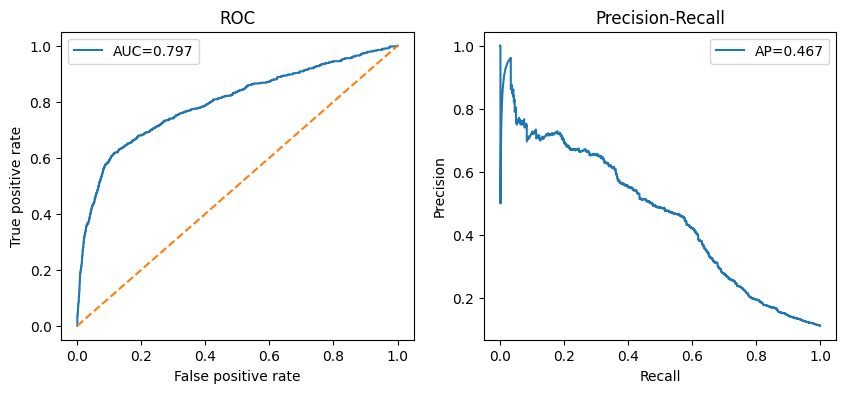

cut=0.3451 called=659 precision=0.513 recall=0.456 lift=4.55
TP 338 FN 404 FP 321 TN 5525


In [26]:
final = best["rf"]          
final.fit(X_dev, y_dev)
s = final.predict_proba(X_hold)[:, 1] if hasattr(final, "predict_proba") else final.decision_function(X_hold)

auc, ap = roc_auc_score(y_hold, s), average_precision_score(y_hold, s)
print("AUC", auc, "AP", ap)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
fpr, tpr, _ = roc_curve(y_hold, s)
ax[0].plot(fpr, tpr, label=f"AUC={auc:.3f}"); ax[0].plot([0, 1], [0, 1], "--")
ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC"); ax[0].legend()
p, r, _ = precision_recall_curve(y_hold, s)
ax[1].plot(r, p, label=f"AP={ap:.3f}")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall"); ax[1].legend()
plt.show()

cut = np.quantile(s, 0.90)
pred = (s >= cut).astype(int)
tn, fp, fn, tp = confusion_matrix(y_hold, pred).ravel()
prec, rec = tp / (tp + fp), tp / (tp + fn)
print(f"cut={cut:.4f} called={pred.sum()} precision={prec:.3f} recall={rec:.3f} lift={prec / y_hold.mean():.2f}")
print("TP", tp, "FN", fn, "FP", fp, "TN", tn)

## Stage 8 · Saving the model

The chosen pipeline (RandomForest with `min_samples_leaf=20`, `max_depth=None`, 200 trees) was refitted on all of `train.csv` (32 940 rows) and saved with `joblib.dump` as `model.joblib` (15.5 MB, under the 50 MB limit). The pipeline contains only scikit-learn parts, so it loads in a fresh Python process from the repository root; it takes the raw `test.csv` columns without `id` and `duration`, with no manual step.

`predictions.csv` has the columns `id`, `y_pred`, `y_score`, 8 236 rows (one per `id` in `test.csv`, all ids unique). `y_score` is the predicted probability of "yes". `y_pred = 1` for the 824 clients (10.0%) with the highest scores, which is the 10% capacity rule applied to the test list.

Check in a fresh process (from the repo root):
`python -c "import joblib; joblib.load('model.joblib')"`, then scoring a few raw rows of `test.csv`.

In [27]:
final_full = clone(final)
final_full.fit(X, y)
joblib.dump(final_full, "model.joblib")
print("MB:", os.path.getsize("model.joblib") / 1e6)

X_test = test[X.columns]
sc_test = (final_full.predict_proba(X_test)[:, 1] if hasattr(final_full, "predict_proba")
           else final_full.decision_function(X_test))
cut_t = np.quantile(sc_test, 0.90)
out = pd.DataFrame({"id": test["id"], "y_pred": (sc_test >= cut_t).astype(int), "y_score": sc_test})
out.to_csv("predictions.csv", index=False)
print(out.shape, out["y_pred"].mean(), out["id"].nunique() == len(test))

MB: 15.498043
(8236, 3) 0.10004856726566294 True
